In [1]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from src.pre_process_filter import build_table, FEATURE_NAMES

In [2]:
table = build_table("../data/hapt_raw/RawData")
print(table.shape)
print(table["activity"].value_counts())
table.head()

(5605, 29)
activity
standing        1979
sitting         1801
walking         1722
stand_to_sit      70
sit_to_stand      33
Name: count, dtype: int64


,user,activity,mean_acc_x,mean_acc_y,mean_acc_z,mean_gyro_x,mean_gyro_y,mean_gyro_z,std_acc_x,std_acc_y,...,min_gyro_z,max_acc_x,max_acc_y,max_acc_z,max_gyro_x,max_gyro_y,max_gyro_z,change_acc_x,change_acc_y,change_acc_z
0,1,standing,1.019365,-0.124227,0.099631,0.007699,-0.002806,0.002277,0.001589,0.003273,...,-0.010370,1.022712,-0.116858,0.109164,0.042735,0.008227,0.014257,0.000212,-0.001669,-0.003265
1,1,standing,1.019427,-0.123014,0.096925,0.014400,-0.004083,0.003807,0.001920,0.005011,...,-0.010370,1.024654,-0.109612,0.104554,0.059664,0.004765,0.024099,-0.000087,0.004094,-0.002147
2,1,standing,1.019900,-0.125065,0.092817,0.007815,-0.007051,0.005730,0.002883,0.006448,...,-0.009635,1.027009,-0.109612,0.104554,0.059664,0.004352,0.029946,0.001034,-0.008197,-0.006068
3,1,standing,1.020378,-0.130490,0.087506,-0.002972,-0.004509,0.003714,0.002558,0.004021,...,-0.013885,1.027009,-0.117068,0.097712,0.024916,0.008460,0.029946,-0.000078,-0.002652,-0.004554
4,1,standing,1.020225,-0.130187,0.085049,0.001289,-0.000352,0.000610,0.001988,0.003886,...,-0.015214,1.025283,-0.121788,0.093337,0.045118,0.015344,0.021881,-0.000229,0.003257,-0.000360


In [3]:
table.to_csv("../data/hapt_filtered.csv", index=False)

In [4]:
TEST_USERS = [2, 4, 9, 10, 12, 13, 18, 20, 24]
BASE = FEATURE_NAMES[:24] # the original 24 features

train = table[table["user"].isin(TEST_USERS) == False]
test = table[table["user"].isin(TEST_USERS)]

X_train = train[BASE]
y_train = train["activity"]
X_test = test[BASE]
y_test = test["activity"]

print("Training windows:", len(train))
print("Test windows:", len(test))

Training windows: 4012
Test windows: 1593


In [5]:
results = {}

def runModel(model, name):
    predictions = model.predict(X_test)
    print(name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print(classification_report(y_test, predictions))
    results[name] = f1_score(y_test, predictions, average="macro")
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation=45)
    plt.title(name)
    plt.tight_layout()
    plt.show()

Baseline (24 features)
Accuracy: 0.9158819836785939
              precision    recall  f1-score   support

sit_to_stand       1.00      0.90      0.95        10
     sitting       0.90      0.84      0.87       508
stand_to_sit       0.86      0.83      0.84        23
    standing       0.86      0.92      0.89       556
     walking       1.00      1.00      1.00       496

    accuracy                           0.92      1593
   macro avg       0.92      0.90      0.91      1593
weighted avg       0.92      0.92      0.92      1593



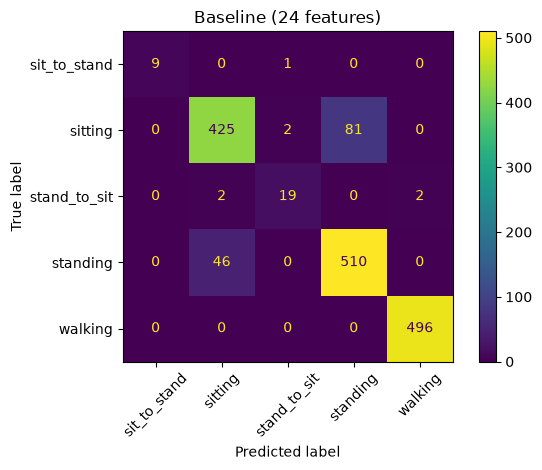

In [6]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
runModel(model, "Baseline (24 features)")

min_acc_y     0.108440
mean_acc_y    0.088810
max_acc_x     0.083974
max_acc_y     0.076801
std_acc_x     0.072446
std_acc_y     0.066131
std_gyro_z    0.061900
std_gyro_y    0.058448
std_gyro_x    0.049996
std_acc_z     0.042913
dtype: float64


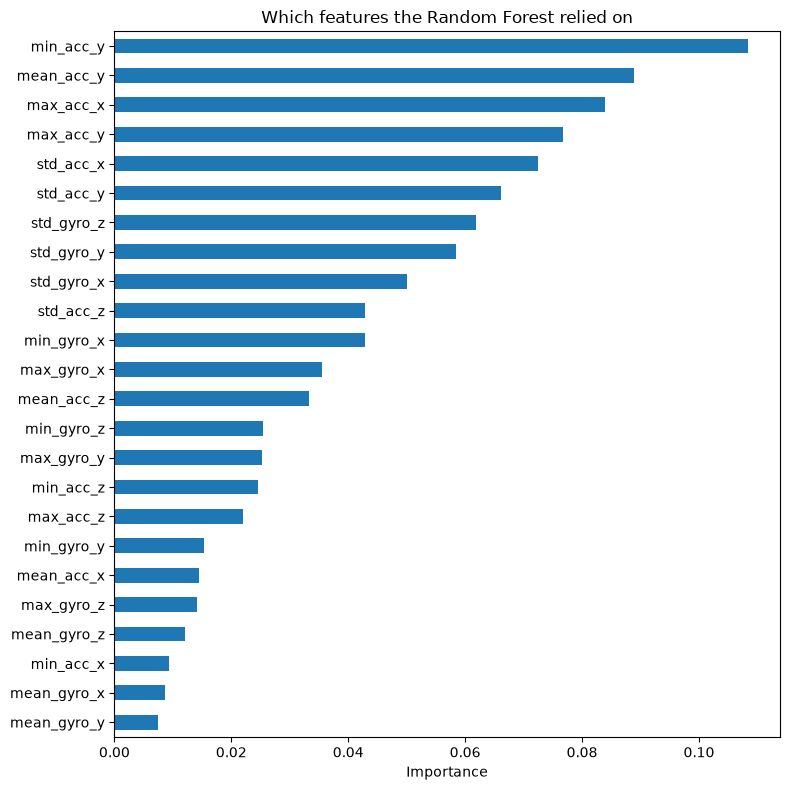

In [7]:
importance = pd.Series(model.feature_importances_, index=BASE)
importance = importance.sort_values(ascending=False)
print(importance.head(10))

importance.plot.barh(figsize=(8, 8))
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Which features the Random Forest relied on")
plt.tight_layout()
plt.show()

Balanced class weights
Accuracy: 0.9127432517263026
              precision    recall  f1-score   support

sit_to_stand       1.00      1.00      1.00        10
     sitting       0.89      0.83      0.86       508
stand_to_sit       0.90      0.78      0.84        23
    standing       0.86      0.91      0.88       556
     walking       1.00      1.00      1.00       496

    accuracy                           0.91      1593
   macro avg       0.93      0.91      0.92      1593
weighted avg       0.91      0.91      0.91      1593



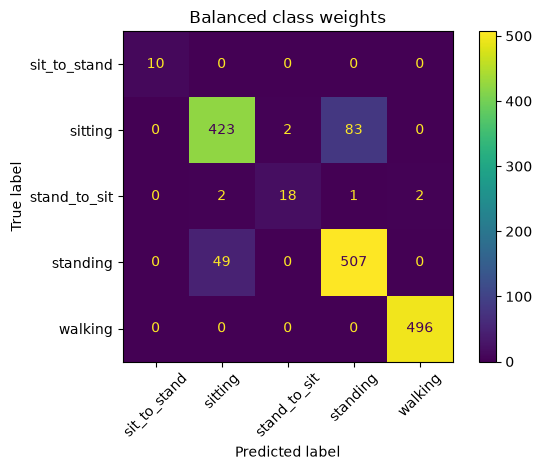

In [8]:
model_balanced = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
model_balanced.fit(X_train, y_train)
runModel(model_balanced, "Balanced class weights")

In [9]:
model_change = RandomForestClassifier(n_estimators=100, random_state=42)
model_change.fit(train[FEATURE_NAMES], y_train)
predictions = model_change.predict(test[FEATURE_NAMES])
print("Macro F1 with change features:", f1_score(y_test, predictions, average="macro"))

Macro F1 with change features: 0.9174287057860198
